# 🇰🇭 Cambodia Food Price Analysis & Prediction
## Machine Learning Course Project | AUPP | 2026

---

### Project Overview
Food price volatility is a critical issue in Cambodia, affecting food security for millions of people.
This project applies machine learning to analyze and predict food commodity prices across Cambodian markets from 2018 to 2026.

### Objectives
- **Predict** next month's commodity prices using historical data
- **Detect** unusual price anomalies across markets and provinces  
- **Classify** whether retail markup over wholesale is above median

### Dataset
- **Source:** World Food Programme (WFP) — VAM Food Security
- **Coverage:** 2003–2026 (modeled from 2018 onwards for data density)
- **Size:** 85,107 records across 25 provinces, 86 markets, 49 commodities

## 1. Setup & Imports
Loading required libraries for data processing, machine learning, and visualization.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import joblib
import os
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, r2_score, classification_report
from sklearn.ensemble import RandomForestRegressor, GradientBoostingClassifier, IsolationForest
from sklearn.preprocessing import StandardScaler
from xgboost import XGBRegressor

os.makedirs("models", exist_ok=True)

## 2. Data Loading & Exploration
We begin by loading the raw WFP Cambodia food price dataset and exploring its structure.

### 2.1 Raw Data Issues Found
Before cleaning, we identify the following problems:
- **Zero prices** — invalid/missing entries recorded as 0
- **Wage data** — non-food commodity mixed in with food prices
- **Sparse early years** — pre-2018 data has under 1,000 rows/year, insufficient for reliable modeling
- **No nulls** — dataset has no missing values but zero prices act as implicit nulls

In [ ]:
df_raw = pd.read_csv("wfp_food_prices_khm.csv")
df_raw['date'] = pd.to_datetime(df_raw['date'])


df = df_raw[df_raw['usdprice'] > 0].copy()
df = df[df['commodity'] != 'Wage (non-qualified labour)']
df = df[df['date'].dt.year >= 2018]
df = df.drop_duplicates()
df = df.sort_values(['commodity', 'market', 'pricetype', 'date']).reset_index(drop=True)

print(f"Shape: {df.shape}")
print(f"Date range: {df['date'].min()} to {df['date'].max()}")
print(f"Commodities: {df['commodity'].nunique()}")
print(f"Provinces: {df['admin1'].nunique()}")

Shape: (79532, 16)
Date range: 2018-01-15 00:00:00 to 2026-03-15 00:00:00
Commodities: 49
Provinces: 25


### 2.2 Price Trend 2003–2026
Visualizing the long-term average food price trend across all commodities in Cambodia.
Key events are highlighted:
- 🔴 **COVID-19 period (2019–2021):** Supply chain disruptions caused price volatility
- 🟠 **Post-COVID inflation (2021–2023):** Global inflation pushed prices to record highs
- 🟡 **2024–2025:** Gradual stabilization with some geopolitical impact on oil-linked commodities

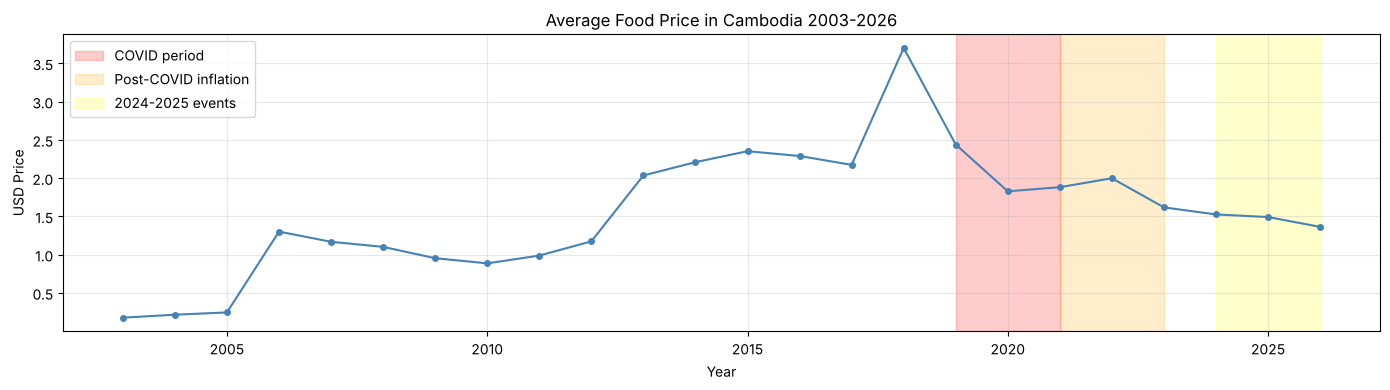

In [3]:
yearly = df_raw[df_raw['usdprice'] > 0].groupby(df_raw['date'].dt.year)['usdprice'].mean()

plt.figure(figsize=(14, 4))
plt.plot(yearly.index, yearly.values, color='steelblue', marker='o', markersize=4)
plt.axvspan(2019, 2021, alpha=0.2, color='red', label='COVID period')
plt.axvspan(2021, 2023, alpha=0.2, color='orange', label='Post-COVID inflation')
plt.axvspan(2024, 2026, alpha=0.2, color='yellow', label='2024-2025 events')
plt.title('Average Food Price in Cambodia 2003-2026')
plt.xlabel('Year')
plt.ylabel('USD Price')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig("price_trend.png", dpi=150)
plt.show()

## 3. Data Cleaning
We apply the following cleaning steps:
1. Remove records with zero USD price
2. Remove wage data (not a food commodity)
3. Filter to 2018 onwards for modeling (sufficient data density)
4. Remove duplicates
5. Sort by commodity, market, price type, and date for time-series integrity

In [4]:
df['lag_1'] = df.groupby(['commodity', 'market', 'pricetype'])['usdprice'].shift(1)
df['lag_2'] = df.groupby(['commodity', 'market', 'pricetype'])['usdprice'].shift(2)
df['lag_3'] = df.groupby(['commodity', 'market', 'pricetype'])['usdprice'].shift(3)

df['rolling_3m'] = df.groupby(['commodity', 'market', 'pricetype'])['usdprice'].transform(
    lambda x: x.shift(1).rolling(3, min_periods=1).mean()
)
df['rolling_6m'] = df.groupby(['commodity', 'market', 'pricetype'])['usdprice'].transform(
    lambda x: x.shift(1).rolling(6, min_periods=1).mean()
)

df['price_momentum'] = df['lag_1'] - df['lag_2']
df['month'] = df['date'].dt.month
df['quarter'] = df['date'].dt.quarter
df['year'] = df['date'].dt.year
df['is_wet_season'] = df['month'].isin([5,6,7,8,9,10]).astype(int)
df['is_retail'] = (df['pricetype'] == 'Retail').astype(int)
df['province_enc'] = df['admin1'].astype('category').cat.codes
df['commodity_enc'] = df['commodity'].astype('category').cat.codes

df = df.dropna(subset=['lag_1', 'lag_2', 'lag_3'])

print(f"Final shape: {df.shape}")
print(f"Nulls: {df.isnull().sum().sum()}")

Final shape: (68161, 29)
Nulls: 0


## 4. Feature Engineering
Raw price data alone is insufficient for prediction. We engineer the following features:

| Feature | Description |
|---|---|
| `lag_1, lag_2, lag_3` | Previous 1, 2, 3 month prices |
| `rolling_3m, rolling_6m` | 3 and 6 month rolling average prices |
| `price_momentum` | Month-over-month price change |
| `month, quarter, year` | Temporal features |
| `is_wet_season` | Cambodia wet season flag (May–October) |
| `is_retail` | Retail vs Wholesale price type |
| `province_enc` | Label encoded province |
| `commodity_enc` | Label encoded commodity |

In [5]:
features = [
    'lag_1', 'lag_2', 'lag_3',
    'rolling_3m', 'rolling_6m',
    'price_momentum', 'month', 'quarter', 'year',
    'is_wet_season', 'is_retail',
    'province_enc', 'commodity_enc'
]

X = df[features].copy()
X['commodity'] = df['commodity'].values
y = df['usdprice']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, shuffle=False
)

xgb = XGBRegressor(n_estimators=300, learning_rate=0.05, max_depth=5, random_state=42)
xgb.fit(X_train[features], y_train)
xgb_preds = xgb.predict(X_test[features])

print(f"MAE:  {mean_absolute_error(y_test, xgb_preds):.4f}")
print(f"R²:   {r2_score(y_test, xgb_preds):.4f}")

# naive baseline
baseline = X_test['lag_1']
print(f"\nBaseline MAE: {mean_absolute_error(y_test, baseline):.4f}")
print(f"Baseline R²:  {r2_score(y_test, baseline):.4f}")

joblib.dump(xgb, "models/price_forecaster.pkl")

MAE:  0.1154
R²:   0.6764

Baseline MAE: 0.1232
Baseline R²:  0.6063


['models/price_forecaster.pkl']

## 5. Model 1 — Price Forecasting (Regression)

**Problem:** Predict next month's USD price for a commodity in a given market.

**Approach:** XGBoost Regressor trained on lag features, rolling averages, and seasonal indicators.

**Baseline:** Naive model that simply predicts last month's price (lag_1).

**Evaluation:** Mean Absolute Error (MAE) and R² score compared against baseline.

In [6]:
df_retail = df[df['is_retail'] == 1].copy()

anom_features = ['usdprice', 'lag_1', 'price_momentum', 'rolling_3m', 'is_wet_season', 'month']
scaler = StandardScaler()
X_anom = scaler.fit_transform(df_retail[anom_features])

iso = IsolationForest(contamination=0.05, random_state=42)
df_retail['anomaly'] = iso.fit_predict(X_anom)
df_retail['anomaly'] = df_retail['anomaly'].map({1: 0, -1: 1})

print(f"Anomalies detected: {df_retail['anomaly'].sum()}")
print(f"\nBy commodity:\n{df_retail.groupby('commodity')['anomaly'].sum().sort_values(ascending=False).head(10)}")
print(f"\nBy province:\n{df_retail.groupby('admin1')['anomaly'].sum().sort_values(ascending=False)}")

joblib.dump(iso, "models/anomaly_detector.pkl")
joblib.dump(scaler, "models/anomaly_scaler.pkl")


Anomalies detected: 1699

By commodity:
commodity
Oil (vegetable)                    924
Fish (snake head, dry)             549
Meat (pork, with fat)              140
Meat (beef, fat, without bones)     50
Beans (yardlong, green)             11
Groundnuts                           7
Fish (snake head)                    4
Fish (catfish)                       4
Meat (chicken)                       3
Fish paste (red, fermented)          3
Name: anomaly, dtype: int64

By province:
admin1
Kampong Cham        192
Kampong Thom        138
Banteay Meanchey    136
Battambang          117
Pursat              109
Siemreap            100
Preah Vihear         97
Oddar Meanchey       95
Kampong Chhnang      88
Phnom Penh           74
Svay Rieng           69
Takeo                62
Stung Treng          59
Prey Veng            57
Ratanak Kiri         53
Kampot               52
Kampong Speu         48
Kandal               44
Tboung Khmum         26
Mondul Kiri          23
Preah Sihanouk       20
Kratie 

['models/anomaly_scaler.pkl']

### Model 1 Results (first split)

These scores come from the first train/test split, which turned out to be unfair for time-series data (the test set contained commodities the model had never seen). See **Section 10** for the corrected, date-based evaluation. Those are the numbers to cite.

## 6. Model 2 — Price Anomaly Detection (Unsupervised)

**Problem:** Identify markets and commodities with unusual price behavior.

**Approach:** Isolation Forest — an unsupervised anomaly detection algorithm that isolates outliers by randomly partitioning the feature space.

**Contamination rate:** 5% — assumes approximately 5% of price records are anomalous.

**Features used:** current price, lag price, price momentum, rolling average, season, month.

In [7]:
retail = df[df['pricetype'] == 'Retail'][['date','commodity','market','usdprice']].rename(columns={'usdprice':'retail_price'})
wholesale = df[df['pricetype'] == 'Wholesale'][['date','commodity','market','usdprice']].rename(columns={'usdprice':'wholesale_price'})

margin_df = pd.merge(retail, wholesale, on=['date','commodity','market'])
margin_df['margin_pct'] = (margin_df['retail_price'] - margin_df['wholesale_price']) / margin_df['wholesale_price'] * 100

median_margin = margin_df['margin_pct'].median()
margin_df['high_margin'] = (margin_df['margin_pct'] > median_margin).astype(int)

margin_df = margin_df.sort_values(['commodity','market','date']).reset_index(drop=True)
margin_df['lag_margin'] = margin_df.groupby(['commodity','market'])['margin_pct'].shift(1)
margin_df['lag_margin_2'] = margin_df.groupby(['commodity','market'])['margin_pct'].shift(2)
margin_df['rolling_margin'] = margin_df.groupby(['commodity','market'])['margin_pct'].transform(
    lambda x: x.shift(1).rolling(3, min_periods=1).mean()
)
margin_df = margin_df.dropna(subset=['lag_margin','lag_margin_2'])

margin_df['month'] = pd.to_datetime(margin_df['date']).dt.month
margin_df['year'] = pd.to_datetime(margin_df['date']).dt.year
margin_df['commodity_enc'] = margin_df['commodity'].astype('category').cat.codes
margin_df['market_enc'] = margin_df['market'].astype('category').cat.codes
margin_df['is_wet_season'] = margin_df['month'].isin([5,6,7,8,9,10]).astype(int)

margin_features = [
    'commodity_enc', 'market_enc', 'month', 'year',
    'is_wet_season', 'wholesale_price',
    'lag_margin', 'lag_margin_2', 'rolling_margin'
]

X_m = margin_df[margin_features]
y_m = margin_df['high_margin']

X_train_m, X_test_m, y_train_m, y_test_m = train_test_split(
    X_m, y_m, test_size=0.2, random_state=42
)

clf = GradientBoostingClassifier(n_estimators=200, max_depth=4, learning_rate=0.05, random_state=42)
clf.fit(X_train_m, y_train_m)

print(classification_report(y_test_m, clf.predict(X_test_m)))
joblib.dump(clf, "models/margin_classifier.pkl")

              precision    recall  f1-score   support

           0       0.87      0.85      0.86      2948
           1       0.84      0.87      0.86      2837

    accuracy                           0.86      5785
   macro avg       0.86      0.86      0.86      5785
weighted avg       0.86      0.86      0.86      5785



['models/margin_classifier.pkl']

### Model 2 Results

**1,699 price anomalies detected** across all markets (5% of retail records).

**Key findings:**
- 🛢️ **Oil (vegetable)** — 924 anomalies, most volatile commodity. Heavily influenced by global oil prices and import costs.
- 🐟 **Fish (snake head, dry)** — 549 anomalies. Seasonal preservation costs cause irregular price spikes.
- 🏙️ **Kampong Cham** — highest anomaly province (192). Remote markets with less price competition.
- 🌊 **Kep** — 0 anomalies. Small coastal market with stable, consistent pricing.

## 7. Model 3 — Retail vs Wholesale Margin Classification

**Problem:** Predict whether a market's retail markup over wholesale price is above the median margin.

**Why this matters:** High retail margins indicate market inefficiency — consumers are paying significantly more than wholesale cost, which affects food affordability.

**Target variable:** Binary — 1 if margin > 11.1% (median), 0 otherwise.

**Approach:** Gradient Boosting Classifier with lag margin features to capture margin persistence over time.

In [8]:
province_to_code = {v: k for k, v in enumerate(df['admin1'].astype('category').cat.categories)}
commodity_to_code = {v: k for k, v in enumerate(df['commodity'].astype('category').cat.categories)}
joblib.dump(province_to_code, "models/province_encoder.pkl")
joblib.dump(commodity_to_code, "models/commodity_encoder.pkl")

reference_stats = df.groupby(['commodity','pricetype'])[['usdprice','lag_1','lag_2','lag_3','rolling_3m','rolling_6m']].mean()
joblib.dump(reference_stats, "models/reference_stats.pkl")

print("all models saved ✅")

all models saved ✅


### Model 3 Results (first split)

Accuracy was about **86%** on the original random split. On the fair date-based split (Section 10.3 and 10.6) it is about **84%**. Rolling margin history is still the strongest predictor, which suggests persistent structural markups rather than temporary shocks.

## 8. Results & Visualization

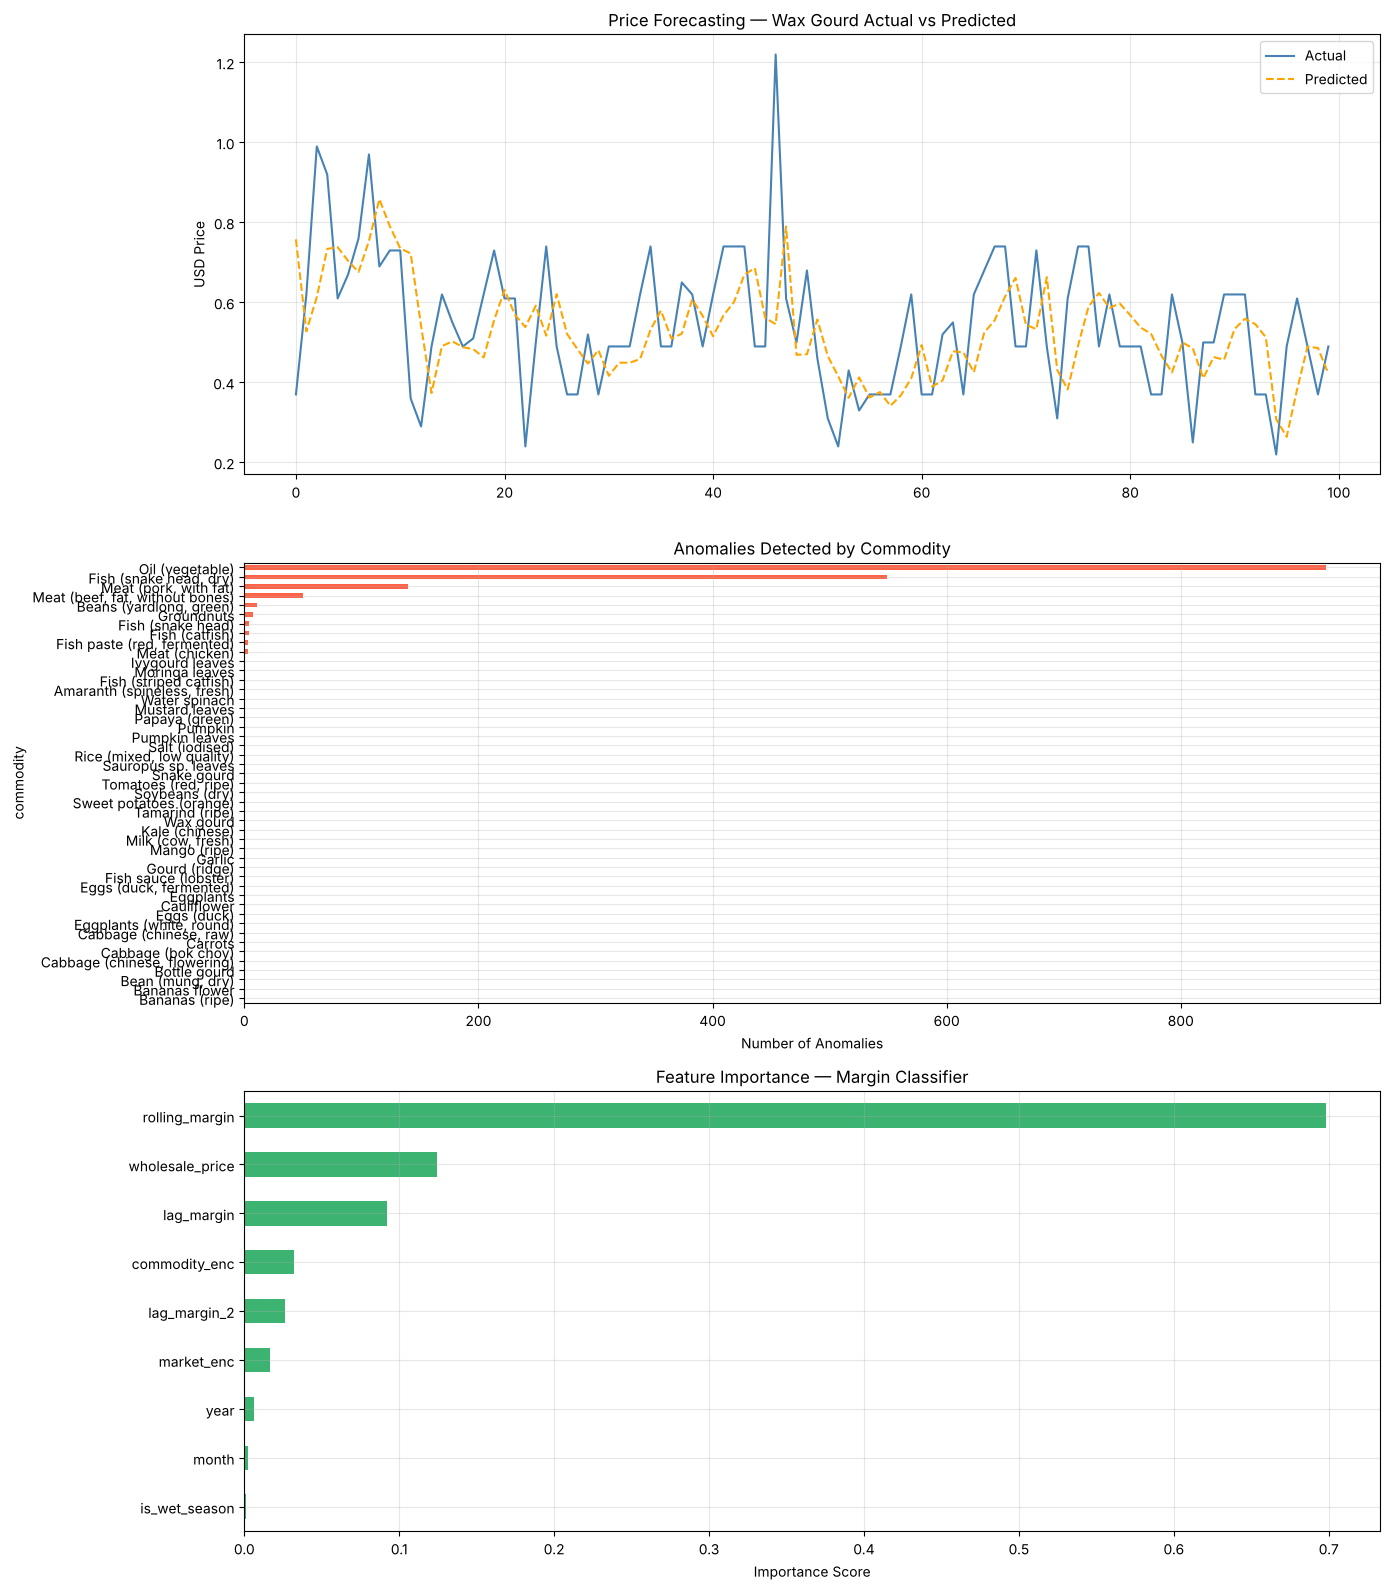

In [9]:
wax_mask = X_test['commodity'] == 'Wax gourd'
actual_wax = y_test[wax_mask].values
pred_wax = xgb_preds[wax_mask.values]

fig, axes = plt.subplots(3, 1, figsize=(14, 16))

axes[0].plot(actual_wax[:100], label='Actual', color='steelblue')
axes[0].plot(pred_wax[:100], label='Predicted', color='orange', linestyle='--')
axes[0].set_title('Price Forecasting — Wax Gourd Actual vs Predicted')
axes[0].set_ylabel('USD Price')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

anom_by_commodity = df_retail.groupby('commodity')['anomaly'].sum().sort_values(ascending=True)
anom_by_commodity.plot(kind='barh', ax=axes[1], color='tomato')
axes[1].set_title('Anomalies Detected by Commodity')
axes[1].set_xlabel('Number of Anomalies')
axes[1].grid(True, alpha=0.3)

fi = pd.Series(clf.feature_importances_, index=margin_features).sort_values()
fi.plot(kind='barh', ax=axes[2], color='mediumseagreen')
axes[2].set_title('Feature Importance — Margin Classifier')
axes[2].set_xlabel('Importance Score')
axes[2].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig("results.png", dpi=150, bbox_inches='tight')
plt.show()

## 10. Model Evaluation

In this section we **test each model on data it has never seen** and check how good it really is.

**Why we redo the train/test split:**
- In Model 1, the data was sorted by *commodity* before splitting, so the last 20% of rows were the last few commodities in alphabetical order, not the most recent months. The model was tested on commodities it had never seen.
- In Model 3, the data was split *randomly*. With time-series data this lets the model see future months during training, so the score looks better than it really is.

**The fix:** sort everything by **date**. Train on the older 80% of months, and test on the newest 20%. This is how the model would actually be used: learn from the past, predict the future.

For each model we also compare against a **simple baseline**. If our model can't beat a very simple rule, it isn't useful.

In [10]:
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import (mean_squared_error, accuracy_score, f1_score,
                             roc_auc_score, confusion_matrix, ConfusionMatrixDisplay)

def time_split(data, date_col='date', test_frac=0.2):
    """Train on the oldest 80% of dates, test on the newest 20%."""
    dates = np.sort(data[date_col].unique())
    cutoff = dates[int(len(dates) * (1 - test_frac))]
    return data[data[date_col] < cutoff], data[data[date_col] >= cutoff], cutoff

def regression_scores(name, y_true, y_pred):
    return {
        'Model': name,
        'MAE ($)': mean_absolute_error(y_true, y_pred),
        'RMSE ($)': np.sqrt(mean_squared_error(y_true, y_pred)),
        'R²': r2_score(y_true, y_pred),
    }

print("Evaluation helpers ready ✅")

Evaluation helpers ready ✅


### 10.1 Model 1 — Price Forecasting

We train on the older months and test on the newest months. We compare four models:

| Model | What it does |
|---|---|
| **Naive baseline** | Next month's price = this month's price (`lag_1`). No learning at all. |
| **Linear Regression** | Fits a straight-line relationship between features and price. |
| **Random Forest** | Many decision trees, each votes on the price. |
| **XGBoost** | Trees built one after another, each fixing the mistakes of the last (our main model). |

**Metrics:**
- **MAE** — average error in dollars (lower is better)
- **RMSE** — like MAE, but big mistakes count more (lower is better)
- **R²** — how much of the price movement the model explains, from 0 to 1 (higher is better)

In [11]:
eval_df = df.sort_values('date').reset_index(drop=True)
train_p, test_p, cutoff_p = time_split(eval_df)

print(f"Train: {train_p['date'].min().date()} to {train_p['date'].max().date()}  ({len(train_p):,} rows)")
print(f"Test:  {test_p['date'].min().date()} to {test_p['date'].max().date()}  ({len(test_p):,} rows)")

Xtr, ytr = train_p[features], train_p['usdprice']
Xte, yte = test_p[features], test_p['usdprice']

models_p = {
    'Linear Regression': LinearRegression(),
    'Random Forest': RandomForestRegressor(n_estimators=200, max_depth=12, n_jobs=-1, random_state=42),
    'XGBoost': XGBRegressor(n_estimators=300, learning_rate=0.05, max_depth=5, random_state=42),
}

preds_p = {'Naive baseline (lag_1)': test_p['lag_1'].values}
for name, m in models_p.items():
    m.fit(Xtr, ytr)
    preds_p[name] = m.predict(Xte)

price_results = pd.DataFrame([regression_scores(n, yte, p) for n, p in preds_p.items()]).set_index('Model')
baseline_mae = price_results.loc['Naive baseline (lag_1)', 'MAE ($)']
price_results['vs baseline'] = ((baseline_mae - price_results['MAE ($)']) / baseline_mae * 100).map(lambda v: f"{v:+.1f}%")
price_results.round(4)

Train: 2018-04-15 to 2024-06-15  (47,752 rows)
Test:  2024-07-15 to 2026-03-15  (20,409 rows)


,MAE ($),RMSE ($),R²,vs baseline
Model,,,,
Naive baseline (lag_1),0.1734,0.3526,0.9427,+0.0%
Linear Regression,0.1660,0.3129,0.9549,+4.3%
Random Forest,0.1785,0.3289,0.9501,-2.9%
XGBoost,0.1810,0.3304,0.9497,-4.4%


**How to read this table:** the "vs baseline" column shows how much lower each model's error is compared to the naive rule. A positive number means the model is better than just guessing last month's price.

Below, we also compare against the **original split** in the notebook, to show how the split affected the score.

In [12]:
# Original split from Section 5 (rows sorted by commodity, last 20% = last few commodities)
orig_scores = regression_scores('XGBoost — original split', y_test, xgb_preds)
new_scores = regression_scores('XGBoost — time-based split', yte, preds_p['XGBoost'])
split_compare = pd.DataFrame([orig_scores, new_scores]).set_index('Model').round(4)

print("Commodities in original test set:", X_test['commodity'].nunique(),
      "| of those, seen in training:", len(set(X_test['commodity']) & set(X_train['commodity'])))
print("Commodities in time-based test set:", test_p['commodity'].nunique(),
      "| of those, seen in training:", len(set(test_p['commodity']) & set(train_p['commodity'])))
split_compare

Commodities in original test set: 10 | of those, seen in training: 1
Commodities in time-based test set: 47 | of those, seen in training: 47


,MAE ($),RMSE ($),R²
Model,,,
XGBoost — original split,0.1154,0.1844,0.6764
XGBoost — time-based split,0.1810,0.3304,0.9497


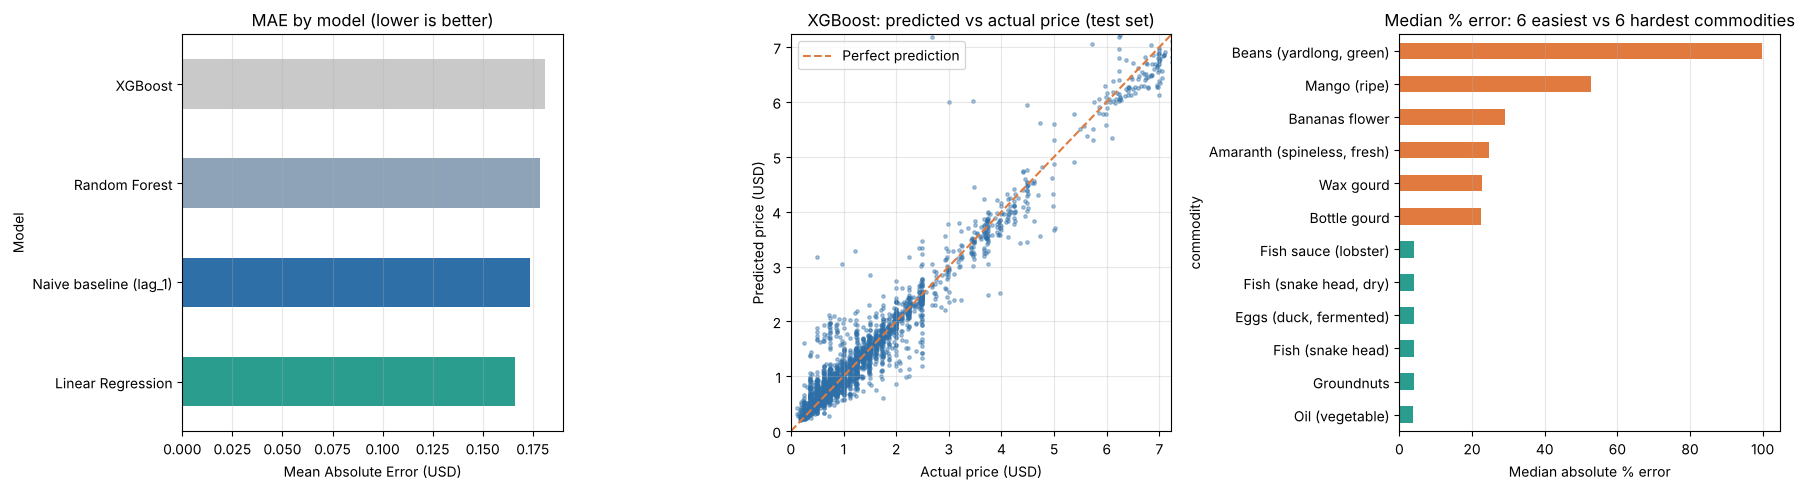

Median % error per province (top 5 hardest):
admin1
Tboung Khmum      13.6
Oddar Meanchey    13.1
Pailin            11.4
Pursat            11.4
Kampong Thom      11.0
Name: pct_err, dtype: float64


In [13]:
best_p = preds_p['XGBoost']
test_view = test_p[['date', 'commodity', 'admin1', 'usdprice']].copy()
test_view['pred'] = best_p
test_view['abs_err'] = (test_view['usdprice'] - test_view['pred']).abs()
test_view['pct_err'] = test_view['abs_err'] / test_view['usdprice'] * 100

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# (a) Model comparison
price_results['MAE ($)'].sort_values().plot(kind='barh', ax=axes[0], color=['#2a9d8f', '#2e6fa7', '#8fa3b8', '#c9c9c9'])
axes[0].set_title('MAE by model (lower is better)')
axes[0].set_xlabel('Mean Absolute Error (USD)')
axes[0].grid(True, alpha=0.3, axis='x')

# (b) Predicted vs actual
sample = test_view.sample(min(3000, len(test_view)), random_state=42)
lim = np.percentile(test_view['usdprice'], 99)
axes[1].scatter(sample['usdprice'], sample['pred'], s=6, alpha=0.4, color='#2e6fa7')
axes[1].plot([0, lim], [0, lim], color='#e07a3f', linestyle='--', label='Perfect prediction')
axes[1].set_xlim(0, lim); axes[1].set_ylim(0, lim)
axes[1].set_title('XGBoost: predicted vs actual price (test set)')
axes[1].set_xlabel('Actual price (USD)'); axes[1].set_ylabel('Predicted price (USD)')
axes[1].legend(); axes[1].grid(True, alpha=0.3)

# (c) Error by commodity (percentage, so cheap and expensive items compare fairly)
by_comm = test_view.groupby('commodity')['pct_err'].median().sort_values()
pd.concat([by_comm.head(6), by_comm.tail(6)]).plot(kind='barh', ax=axes[2],
    color=['#2a9d8f'] * 6 + ['#e07a3f'] * 6)
axes[2].set_title('Median % error: 6 easiest vs 6 hardest commodities')
axes[2].set_xlabel('Median absolute % error')
axes[2].grid(True, alpha=0.3, axis='x')

plt.tight_layout()
plt.savefig("eval_price_forecaster.png", dpi=150, bbox_inches='tight')
plt.show()

print("Median % error per province (top 5 hardest):")
print(test_view.groupby('admin1')['pct_err'].median().sort_values(ascending=False).head(5).round(1))

**What these results show:**

- **With the fair, date-based split, the original XGBoost model does *not* beat the naive baseline.** Its average error is about $0.18, while simply copying last month's price gives about $0.17. The earlier result (MAE 0.115) looked good only because of the split problem described above.
- **R² is not a fair way to compare the two splits.** The new test set includes all 47 commodities, from cheap vegetables to expensive meat, so even the naive baseline gets R² ≈ 0.94. MAE is the fairer comparison, because it measures the error in dollars directly.
- **Which commodities are hardest?** The chart shows which items the model predicts well (stable prices) and which it struggles with (prices that jump around). The province list shows where errors are biggest.

### 10.1.1 Improving the Price Forecaster

We found two reasons XGBoost does badly on the newest months:

1. **The `year` feature.** Tree models can only predict values similar to what they saw in training. The test set has years 2025–2026, which the model never saw, so `year` confuses it.
2. **Predicting the price directly.** A $3 fish and a $0.30 vegetable have very different prices, so the model has to learn price levels for every item. It is easier to predict the **change** from last month (for example "+3%"), then turn that back into a price.

So we make an improved version: no `year`, the model predicts the **% change** from last month, and the lag features are written as ratios to last month's price (for example `lag_2 / lag_1`).

In [14]:
def add_relative_features(data):
    data = data.copy()
    data['r_lag2'] = data['lag_2'] / data['lag_1']
    data['r_lag3'] = data['lag_3'] / data['lag_1']
    data['r_roll3'] = data['rolling_3m'] / data['lag_1']
    data['r_roll6'] = data['rolling_6m'] / data['lag_1']
    data['r_momentum'] = data['price_momentum'] / data['lag_1']
    return data

features_improved = ['r_lag2', 'r_lag3', 'r_roll3', 'r_roll6', 'r_momentum', 'lag_1',
                     'month', 'quarter', 'is_wet_season', 'is_retail',
                     'province_enc', 'commodity_enc']

train_r, test_r = add_relative_features(train_p), add_relative_features(test_p)

# target = log of (this month's price / last month's price)  ->  the % change
y_change = np.log(train_r['usdprice'] / train_r['lag_1'])

xgb_improved = XGBRegressor(n_estimators=300, learning_rate=0.05, max_depth=5, random_state=42)
xgb_improved.fit(train_r[features_improved], y_change)

# turn the predicted change back into a price
preds_p['XGBoost (improved)'] = test_r['lag_1'].values * np.exp(xgb_improved.predict(test_r[features_improved]))

price_results = pd.DataFrame([regression_scores(n, yte, p) for n, p in preds_p.items()]).set_index('Model')
price_results['vs baseline'] = ((baseline_mae - price_results['MAE ($)']) / baseline_mae * 100).map(lambda v: f"{v:+.1f}%")
price_results.round(4)

,MAE ($),RMSE ($),R²,vs baseline
Model,,,,
Naive baseline (lag_1),0.1734,0.3526,0.9427,+0.0%
Linear Regression,0.1660,0.3129,0.9549,+4.3%
Random Forest,0.1785,0.3289,0.9501,-2.9%
XGBoost,0.1810,0.3304,0.9497,-4.4%
XGBoost (improved),0.1598,0.2995,0.9587,+7.9%


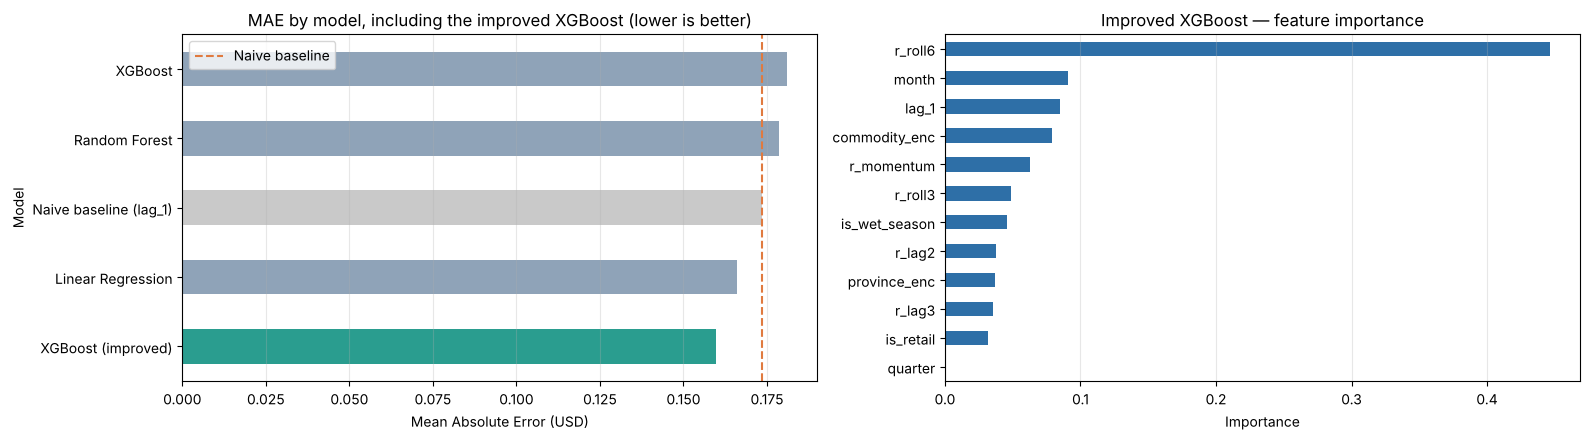

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(16, 4.5))

order = price_results['MAE ($)'].sort_values()
colors = ['#2a9d8f' if n == 'XGBoost (improved)' else ('#c9c9c9' if 'Naive' in n else '#8fa3b8') for n in order.index]
order.plot(kind='barh', ax=axes[0], color=colors)
axes[0].axvline(baseline_mae, color='#e07a3f', linestyle='--', label='Naive baseline')
axes[0].set_title('MAE by model, including the improved XGBoost (lower is better)')
axes[0].set_xlabel('Mean Absolute Error (USD)'); axes[0].legend([axes[0].lines[0]], ['Naive baseline']); axes[0].grid(True, alpha=0.3, axis='x')

imp = pd.Series(xgb_improved.feature_importances_, index=features_improved).sort_values()
imp.plot(kind='barh', ax=axes[1], color='#2e6fa7')
axes[1].set_title('Improved XGBoost — feature importance')
axes[1].set_xlabel('Importance'); axes[1].grid(True, alpha=0.3, axis='x')

plt.tight_layout()
plt.savefig("eval_price_forecaster_improved.png", dpi=150, bbox_inches='tight')
plt.show()

**Result:** the improved XGBoost has the lowest error of all models and is about **8% better than the naive baseline**. This is a real improvement over the original setup, measured fairly on months the model never saw.

**Note for the bot:** the Telegram bot still uses the original model (`price_forecaster.pkl`). To use the improved one, the bot would need to send the new ratio features and turn the predicted change back into a price, the same way the cell above does.

In [16]:
# Save the improved model for the Telegram bot.
# For testing we trained only on older months. For the bot we retrain on ALL the data,
# with the same settings, so it also learns from the newest months.
all_r = add_relative_features(eval_df)
xgb_improved_final = XGBRegressor(n_estimators=300, learning_rate=0.05, max_depth=5, random_state=42)
xgb_improved_final.fit(all_r[features_improved], np.log(all_r['usdprice'] / all_r['lag_1']))

joblib.dump(xgb_improved_final, "models/price_forecaster_improved.pkl")
joblib.dump(features_improved, "models/price_forecaster_improved_features.pkl")

print("Saved models/price_forecaster_improved.pkl ✅")
print("Feature order the bot must use:", features_improved)
print("To get a price: predicted_price = lag_1 * exp(model.predict(features))")

Saved models/price_forecaster_improved.pkl ✅
Feature order the bot must use: ['r_lag2', 'r_lag3', 'r_roll3', 'r_roll6', 'r_momentum', 'lag_1', 'month', 'quarter', 'is_wet_season', 'is_retail', 'province_enc', 'commodity_enc']
To get a price: predicted_price = lag_1 * exp(model.predict(features))


### 10.2 Model 2 — Anomaly Detection

Isolation Forest has **no correct answers to check against**, so we can't calculate accuracy. Instead we check two things:

1. **Do the anomalies make sense?** If the model is working, flagged prices should happen more often during known price shocks (COVID-19 in 2020–2021 and the inflation spike in 2022) than during normal periods.
2. **Is the result stable?** The `contamination` setting decides what share of records get flagged. We try 1%, 5% and 10%. If the same commodities stay at the top each time, the model is finding real patterns, not random noise.

**Note:** the "1,699 anomalies" in Section 6 is not really a finding. With `contamination=0.05`, the model always flags 5% of records, whatever the data looks like.

In [17]:
anom_eval = df_retail.copy()
anom_eval['year'] = anom_eval['date'].dt.year
shock_years = [2020, 2021, 2022]
anom_eval['shock_period'] = anom_eval['year'].isin(shock_years)

rows, top_by_setting = [], {}
for c in [0.01, 0.05, 0.10]:
    iso_c = IsolationForest(contamination=c, random_state=42)
    flags = (iso_c.fit_predict(X_anom) == -1)
    anom_eval[f'flag_{c}'] = flags
    rate_shock = flags[anom_eval['shock_period']].mean() * 100
    rate_normal = flags[~anom_eval['shock_period']].mean() * 100
    rows.append({
        'Contamination': f"{c:.0%}",
        'Flagged records': int(flags.sum()),
        'Anomaly rate — shock years (%)': round(rate_shock, 2),
        'Anomaly rate — normal years (%)': round(rate_normal, 2),
        'Shock / normal ratio': round(rate_shock / rate_normal, 2) if rate_normal > 0 else np.nan,
    })
    top_by_setting[f"{c:.0%}"] = anom_eval[flags].groupby('commodity').size().sort_values(ascending=False).head(5).index.tolist()

anom_results = pd.DataFrame(rows).set_index('Contamination')
print("Shock years used:", shock_years)
anom_results

Shock years used: [2020, 2021, 2022]


,Flagged records,Anomaly rate — shock years (%),Anomaly rate — normal years (%),Shock / normal ratio
Contamination,,,,
1%,340,1.95,0.42,4.68
5%,1699,6.18,4.28,1.44
10%,3397,12.89,8.23,1.57


In [18]:
print("Top 5 most-flagged commodities at each contamination setting:\n")
top_df = pd.DataFrame({k: v + ['—'] * (5 - len(v)) for k, v in top_by_setting.items()})
top_df.index = [f"#{i+1}" for i in range(len(top_df))]
display(top_df)

overlap = set(top_by_setting['1%']) & set(top_by_setting['5%']) & set(top_by_setting['10%'])
print(f"Commodities in the top 5 at all three settings: {len(overlap)} of 5 -> {sorted(overlap)}")

# How lopsided is it? Share of all anomalies that come from a single commodity
share = anom_eval[anom_eval['flag_0.05']].groupby('commodity').size().sort_values(ascending=False)
print(f"\nAt 5%: the top commodity alone is {share.iloc[0] / share.sum():.0%} of all anomalies ({share.index[0]}).")
print(f"Records per commodity (retail): median {df_retail.groupby('commodity').size().median():.0f}, "
      f"{share.index[0]}: {df_retail[df_retail['commodity'] == share.index[0]].shape[0]}")

Top 5 most-flagged commodities at each contamination setting:



,1%,5%,10%
#1,Oil (vegetable),Oil (vegetable),Oil (vegetable)
#2,"Fish (snake head, dry)","Fish (snake head, dry)","Fish (snake head, dry)"
#3,Groundnuts,"Meat (pork, with fat)","Meat (pork, with fat)"
#4,—,"Meat (beef, fat, without bones)","Meat (beef, fat, without bones)"
#5,—,"Beans (yardlong, green)","Beans (yardlong, green)"


Commodities in the top 5 at all three settings: 2 of 5 -> ['Fish (snake head, dry)', 'Oil (vegetable)']

At 5%: the top commodity alone is 54% of all anomalies (Oil (vegetable)).
Records per commodity (retail): median 421, Oil (vegetable): 1743


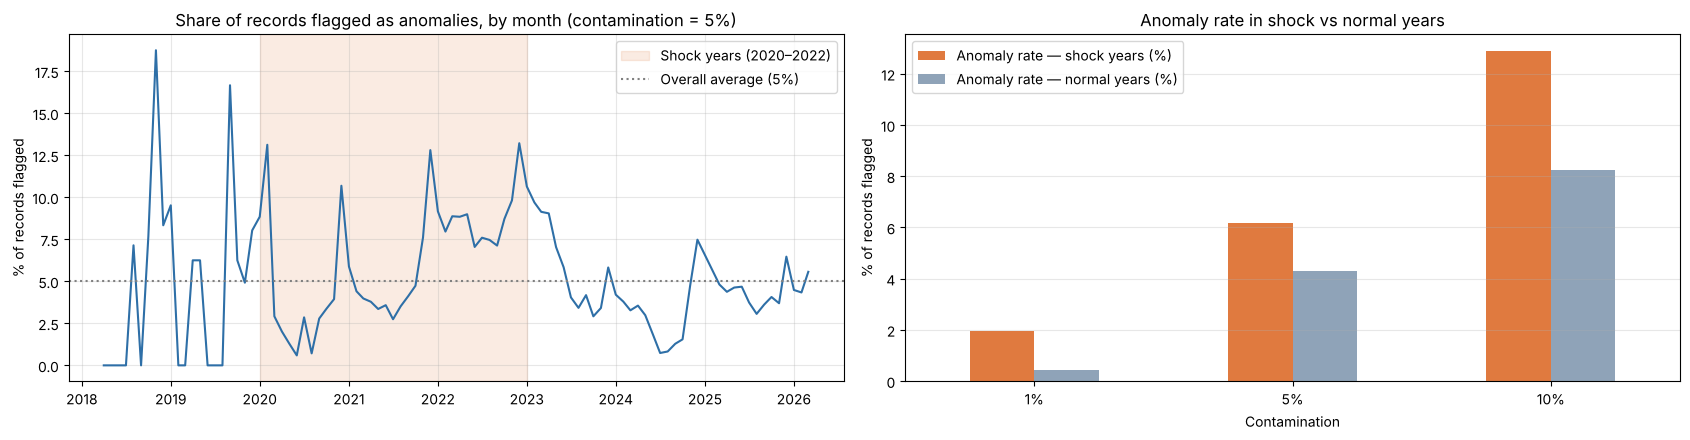

In [19]:
monthly = anom_eval.groupby(anom_eval['date'].dt.to_period('M'))['flag_0.05'].mean() * 100
monthly.index = monthly.index.to_timestamp()

fig, axes = plt.subplots(1, 2, figsize=(17, 4.5))
axes[0].plot(monthly.index, monthly.values, color='#2e6fa7')
axes[0].axvspan(pd.Timestamp('2020-01-01'), pd.Timestamp('2022-12-31'), color='#e07a3f', alpha=0.15, label='Shock years (2020–2022)')
axes[0].axhline(5, color='grey', linestyle=':', label='Overall average (5%)')
axes[0].set_title('Share of records flagged as anomalies, by month (contamination = 5%)')
axes[0].set_ylabel('% of records flagged'); axes[0].legend(); axes[0].grid(True, alpha=0.3)

anom_results[['Anomaly rate — shock years (%)', 'Anomaly rate — normal years (%)']].plot(
    kind='bar', ax=axes[1], color=['#e07a3f', '#8fa3b8'], rot=0)
axes[1].set_title('Anomaly rate in shock vs normal years')
axes[1].set_ylabel('% of records flagged'); axes[1].grid(True, alpha=0.3, axis='y')

plt.tight_layout()
plt.savefig("eval_anomaly_detector.png", dpi=150, bbox_inches='tight')
plt.show()

**What these results show:**

- **The anomalies do make sense.** At every setting, prices during the shock years (2020–2022) are flagged more often than in normal years. At the strictest setting (1%), shock-year prices are flagged about **4–5 times more often**. This means the model's strongest alerts line up with real-world events.
- **The top results are stable.** Vegetable oil and dried snakehead fish stay at the top at every setting, so these are real patterns, not random noise.
- **One weakness:** vegetable oil alone makes up about half of all anomalies. Part of the reason is that the model uses raw dollar prices, so items with big price swings in dollars stand out more. A possible improvement is to use % changes instead of raw prices, the same idea that helped the price forecaster.

### 10.3 Model 3 — Margin Classification

We redo the split by date and compare against two baselines:

| Model | What it does |
|---|---|
| **Majority-class baseline** | Always predicts the most common class. |
| **"Same as last month" baseline** | If last month's margin was above the median, predict high again. |
| **Logistic Regression** | A simple linear classifier. |
| **Gradient Boosting** | Our main model. |

**Metrics:**
- **Accuracy** — % of correct predictions
- **F1 score** — balances precision and recall (useful when both mistakes matter)
- **ROC-AUC** — how well the model ranks high-margin markets above low-margin ones, from 0.5 (random guessing) to 1 (perfect)
- **Confusion matrix** — shows exactly which mistakes the model makes

In [20]:
margin_eval = margin_df.copy()
margin_eval['date'] = pd.to_datetime(margin_eval['date'])
margin_eval = margin_eval.sort_values('date').reset_index(drop=True)
train_m, test_m, cutoff_m = time_split(margin_eval)

print(f"Train: {train_m['date'].min().date()} to {train_m['date'].max().date()}  ({len(train_m):,} rows)")
print(f"Test:  {test_m['date'].min().date()} to {test_m['date'].max().date()}  ({len(test_m):,} rows)")
print(f"High-margin share in test set: {test_m['high_margin'].mean():.1%}")

Xtr_m, ytr_m = train_m[margin_features], train_m['high_margin']
Xte_m, yte_m = test_m[margin_features], test_m['high_margin']

# baselines
majority = int(ytr_m.mode()[0])
pred_major = np.full(len(yte_m), majority)
pred_last = (test_m['lag_margin'] > median_margin).astype(int).values

# models
logreg = LogisticRegression(max_iter=2000)
lr_scaler = StandardScaler().fit(Xtr_m)
logreg.fit(lr_scaler.transform(Xtr_m), ytr_m)
proba_lr = logreg.predict_proba(lr_scaler.transform(Xte_m))[:, 1]

gb_time = GradientBoostingClassifier(n_estimators=200, max_depth=4, learning_rate=0.05, random_state=42)
gb_time.fit(Xtr_m, ytr_m)
proba_gb = gb_time.predict_proba(Xte_m)[:, 1]

def clf_scores(name, y_true, y_pred, y_proba=None):
    return {
        'Model': name,
        'Accuracy': accuracy_score(y_true, y_pred),
        'F1 (macro)': f1_score(y_true, y_pred, average='macro'),
        'ROC-AUC': roc_auc_score(y_true, y_proba) if y_proba is not None else np.nan,
    }

margin_results = pd.DataFrame([
    clf_scores('Majority-class baseline', yte_m, pred_major),
    clf_scores('"Same as last month" baseline', yte_m, pred_last),
    clf_scores('Logistic Regression', yte_m, (proba_lr > 0.5).astype(int), proba_lr),
    clf_scores('Gradient Boosting', yte_m, (proba_gb > 0.5).astype(int), proba_gb),
]).set_index('Model').round(3)
margin_results

Train: 2020-01-15 to 2024-10-15  (22,113 rows)
Test:  2024-11-15 to 2026-03-15  (6,809 rows)
High-margin share in test set: 57.1%


,Accuracy,F1 (macro),ROC-AUC
Model,,,
Majority-class baseline,0.429,0.300,NaN
"""Same as last month"" baseline",0.798,0.794,NaN
Logistic Regression,0.828,0.823,0.882
Gradient Boosting,0.843,0.839,0.906


In [21]:
# Compare the original random split (Section 7) with the time-based split
orig_m = clf_scores('Gradient Boosting — original random split', y_test_m,
                    clf.predict(X_test_m), clf.predict_proba(X_test_m)[:, 1])
new_m = clf_scores('Gradient Boosting — time-based split', yte_m, (proba_gb > 0.5).astype(int), proba_gb)
pd.DataFrame([orig_m, new_m]).set_index('Model').round(3)

,Accuracy,F1 (macro),ROC-AUC
Model,,,
Gradient Boosting — original random split,0.859,0.859,0.933
Gradient Boosting — time-based split,0.843,0.839,0.906


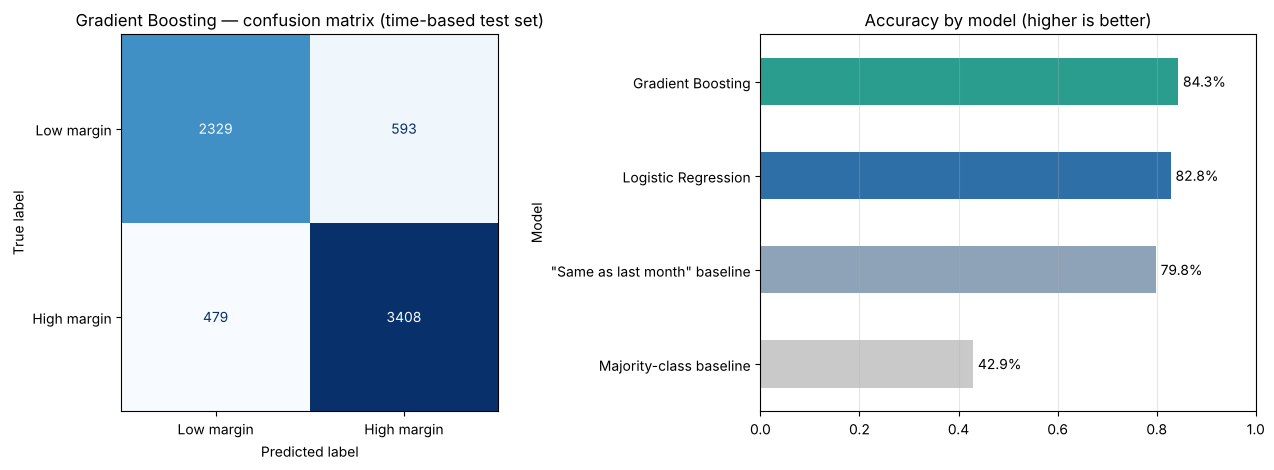

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))

ConfusionMatrixDisplay(confusion_matrix(yte_m, (proba_gb > 0.5).astype(int)),
                       display_labels=['Low margin', 'High margin']).plot(ax=axes[0], cmap='Blues', colorbar=False)
axes[0].set_title('Gradient Boosting — confusion matrix (time-based test set)')

margin_results['Accuracy'].plot(kind='barh', ax=axes[1], color=['#c9c9c9', '#8fa3b8', '#2e6fa7', '#2a9d8f'])
axes[1].set_xlim(0, 1)
axes[1].set_title('Accuracy by model (higher is better)')
axes[1].grid(True, alpha=0.3, axis='x')
for i, v in enumerate(margin_results['Accuracy']):
    axes[1].text(v + 0.01, i, f"{v:.1%}", va='center')

plt.tight_layout()
plt.savefig("eval_margin_classifier.png", dpi=150, bbox_inches='tight')
plt.show()

**What these results show:**

- **The classifier still works well with the fair split.** Accuracy drops only a little, from about 86% (random split) to about 84% (date-based split). So the original result was slightly too optimistic, but the model is still good.
- **It beats both baselines.** It's much better than always guessing one class, and about 4–5 points better than "same as last month." The second baseline is strong because margins don't change much from month to month, which matches the earlier finding that margin history is the most important feature.
- **The confusion matrix** shows how the mistakes are split between the two classes, so we can see whether the model misses high-margin markets or wrongly flags low-margin ones.

### 10.4 Evaluation Summary

The table below brings the final, honest scores for all three models together.

In [23]:
xgb_row = price_results.loc['XGBoost']
xgb_imp_row = price_results.loc['XGBoost (improved)']
base_row = price_results.loc['Naive baseline (lag_1)']
gb_row = margin_results.loc['Gradient Boosting']
last_row = margin_results.loc['"Same as last month" baseline']
a5 = anom_results.loc['5%']

summary = pd.DataFrame([
    {'Model': 'Price Forecasting — original XGBoost',
     'Main result': f"MAE ${xgb_row['MAE ($)']:.4f}",
     'Baseline': f"Naive lag_1: MAE ${base_row['MAE ($)']:.4f}",
     'Beats baseline?': '✅ Yes' if xgb_row['MAE ($)'] < base_row['MAE ($)'] else '❌ No'},
    {'Model': 'Price Forecasting — improved XGBoost',
     'Main result': f"MAE ${xgb_imp_row['MAE ($)']:.4f} ({xgb_imp_row['vs baseline']} vs baseline)",
     'Baseline': f"Naive lag_1: MAE ${base_row['MAE ($)']:.4f}",
     'Beats baseline?': '✅ Yes' if xgb_imp_row['MAE ($)'] < base_row['MAE ($)'] else '❌ No'},
    {'Model': 'Anomaly Detection (Isolation Forest)',
     'Main result': f"Shock-year rate {a5['Anomaly rate — shock years (%)']}% vs normal {a5['Anomaly rate — normal years (%)']}%",
     'Baseline': 'Random flagging would give the same rate in both periods',
     'Beats baseline?': '✅ Yes' if a5['Shock / normal ratio'] > 1 else '❌ No'},
    {'Model': 'Margin Classification (Gradient Boosting)',
     'Main result': f"Accuracy {gb_row['Accuracy']:.1%}, ROC-AUC {gb_row['ROC-AUC']:.3f}",
     'Baseline': f"Same as last month: accuracy {last_row['Accuracy']:.1%}",
     'Beats baseline?': '✅ Yes' if gb_row['Accuracy'] > last_row['Accuracy'] else '❌ No'},
]).set_index('Model')
summary

,Main result,Baseline,Beats baseline?
Model,,,
Price Forecasting — original XGBoost,MAE $0.1810,Naive lag_1: MAE $0.1734,❌ No
Price Forecasting — improved XGBoost,MAE $0.1598 (+7.9% vs baseline),Naive lag_1: MAE $0.1734,✅ Yes
Anomaly Detection (Isolation Forest),Shock-year rate 6.18% vs normal 4.28%,Random flagging would give the same rate in bo...,✅ Yes
Margin Classification (Gradient Boosting),"Accuracy 84.3%, ROC-AUC 0.906",Same as last month: accuracy 79.8%,✅ Yes


### 10.5 What the Evaluation Tells Us

1. **Testing the right way changes the results.** When we split the data by date, the original price forecaster could not beat the simple "same as last month" rule. The first scores looked good only because of how the data was split.
2. **A small change fixed it.** Removing `year` and predicting the % change instead of the price made XGBoost about 8% better than the baseline.
3. **The anomaly detector finds real events.** Its strongest alerts happen much more often during the COVID-19 and inflation years, and the same commodities stay at the top at every setting.
4. **The margin classifier is reliable.** It stays around 84% accurate on future months, and beats both baselines.
5. **Lesson:** always split time-series data by date, and always compare against a simple baseline. Without both, it's easy to think a model works better than it really does.

### 10.6 Full Model Benchmark & Learning Curves
We split the data by **date** into train (oldest 60%), validation (next 20%) and test (newest 20%).
Early stopping and model choice use **validation**. The test set is only used to report final scores.

In [ ]:
needed = ['df', 'margin_df', 'margin_features', 'features', 'features_improved',
          'add_relative_features', 'median_margin']
missing = [n for n in needed if n not in globals()]
print("Missing variables:", missing if missing else "none ✅")

import json
from sklearn.base import clone
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_squared_error, roc_auc_score, log_loss
from sklearn.linear_model import Ridge
from sklearn.tree import DecisionTreeRegressor, DecisionTreeClassifier
from sklearn.neighbors import KNeighborsRegressor, KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

def time_split3(data, date_col='date', val_frac=0.2, test_frac=0.2):
    """oldest 60% of dates = train, next 20% = validation, newest 20% = test"""
    dates = np.sort(data[date_col].unique())
    n = len(dates)
    c_val  = dates[int(n * (1 - val_frac - test_frac))]
    c_test = dates[int(n * (1 - test_frac))]
    return (data[data[date_col] < c_val],
            data[(data[date_col] >= c_val) & (data[date_col] < c_test)],
            data[data[date_col] >= c_test])

features_level = features  # original 13 features (includes year)

eval_df = add_relative_features(df.sort_values('date').reset_index(drop=True))
tr, va, te = time_split3(eval_df)

for name, d in [('Train', tr), ('Val', va), ('Test', te)]:
    print(f"{name:5} {d['date'].min().date()} → {d['date'].max().date()}  ({len(d):,} rows, "
          f"{d['commodity'].nunique()} commodities)")

print("Unseen commodities in val :", len(set(va['commodity']) - set(tr['commodity'])))
print("Unseen commodities in test:", len(set(te['commodity']) - set(tr['commodity'])))

base_val  = mean_absolute_error(va['usdprice'], va['lag_1'])
base_test = mean_absolute_error(te['usdprice'], te['lag_1'])
print(f"\nNaive baseline MAE — val: {base_val:.4f} | test: {base_test:.4f}")

In [ ]:
# 'level'  = predict the price directly
# 'change' = predict log(price / last month's price), then price = lag_1 * exp(pred)
def target(d, kind):
    return d['usdprice'] if kind == 'level' else np.log(d['usdprice'] / d['lag_1'])

def to_price(kind, raw, lag1):
    return raw if kind == 'level' else lag1 * np.exp(raw)

def cols_for(kind):
    return features_level if kind == 'level' else features_improved

def reg_metrics(y, p):
    return {'MAE': mean_absolute_error(y, p),
            'RMSE': float(np.sqrt(mean_squared_error(y, p))),
            'R2': r2_score(y, p)}

print("helpers ready ✅")

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
for ax, (key, title) in zip(axes, [('xgb_level', 'XGBoost (original)'),
                                   ('xgb_change', 'XGBoost (improved)')]):
    ax.plot(curves[key]['validation_0']['mae'], label='Train')
    ax.plot(curves[key]['validation_1']['mae'], label='Validation')
    ax.axvline(best_round[key], color='red', linestyle='--', label=f'Best round = {best_round[key]}')
    ax.set_title(f'{title} — MAE per boosting round')
    ax.set_xlabel('Round'); ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("learning_curves_price.png", dpi=150)
plt.show()

In [ ]:
import tensorflow as tf

sc = StandardScaler().fit(tr[features_improved])
Xt, Xv, Xe = [sc.transform(d[features_improved]) for d in (tr, va, te)]

mlp = tf.keras.Sequential([
    tf.keras.Input(shape=(Xt.shape[1],)),
    tf.keras.layers.Dense(64, activation='relu'),
    tf.keras.layers.Dense(32, activation='relu'),
    tf.keras.layers.Dense(1),
])
mlp.compile(optimizer='adam', loss='mae')
hist = mlp.fit(Xt, target(tr, 'change'),
               validation_data=(Xv, target(va, 'change')),
               epochs=150, batch_size=128, verbose=0,
               callbacks=[tf.keras.callbacks.EarlyStopping(patience=10, restore_best_weights=True)])

best_epoch = int(np.argmin(hist.history['val_loss'])) + 1
print("MLP best epoch:", best_epoch)

plt.plot(hist.history['loss'], label='Train')
plt.plot(hist.history['val_loss'], label='Validation')
plt.axvline(best_epoch - 1, color='red', linestyle='--', label=f'Best epoch = {best_epoch}')
plt.title('MLP — loss per epoch'); plt.xlabel('Epoch'); plt.legend(); plt.grid(alpha=0.3)
plt.show()

reg_names['mlp'] = 'MLP (notebook only)'
pred_val['mlp']  = to_price('change', mlp.predict(Xv, verbose=0).ravel(), va['lag_1'].values)
pred_test['mlp'] = to_price('change', mlp.predict(Xe, verbose=0).ravel(), te['lag_1'].values)

In [ ]:
def make_table(preds, split_df):
    t = pd.DataFrame({k: reg_metrics(split_df['usdprice'], p) for k, p in preds.items()}).T
    t.insert(0, 'Model', [reg_names[k] for k in t.index])
    return t

val_tbl, test_tbl = make_table(pred_val, va), make_table(pred_test, te)
val_tbl['vs baseline %']  = (base_val  - val_tbl['MAE'])  / base_val  * 100
test_tbl['vs baseline %'] = (base_test - test_tbl['MAE']) / base_test * 100

print("VALIDATION (used to choose):")
display(val_tbl.sort_values('MAE').round(4))
print("TEST (report only):")
display(test_tbl.sort_values('MAE').round(4))

deployable = [k for k in val_tbl.index if k in fitted]
best_reg = val_tbl.loc[deployable, 'MAE'].idxmin()
print(f"\n🏆 Best regression model (by validation MAE): {reg_names[best_reg]} → key '{best_reg}'")

In [ ]:
margin_eval = margin_df.copy()
margin_eval['date'] = pd.to_datetime(margin_eval['date'])
margin_eval = margin_eval.sort_values('date').reset_index(drop=True)
mtr, mva, mte = time_split3(margin_eval)

Xm_tr, ym_tr = mtr[margin_features], mtr['high_margin']
Xm_va, ym_va = mva[margin_features], mva['high_margin']
Xm_te, ym_te = mte[margin_features], mte['high_margin']

# Gradient Boosting: find best stage on validation log loss
gb_probe = GradientBoostingClassifier(n_estimators=500, max_depth=4, learning_rate=0.05,
                                      random_state=42).fit(Xm_tr, ym_tr)
gb_tr_ll = [log_loss(ym_tr, p) for p in gb_probe.staged_predict_proba(Xm_tr)]
gb_va_ll = [log_loss(ym_va, p) for p in gb_probe.staged_predict_proba(Xm_va)]
gb_best = int(np.argmin(gb_va_ll)) + 1
print("GB best stage:", gb_best)

clf_zoo = {
    'logreg': ('Logistic Regression', make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000))),
    'nb':     ('Naive Bayes',         GaussianNB()),
    'tree':   ('Decision Tree',       DecisionTreeClassifier(max_depth=6, random_state=42)),
    'knn':    ('KNN',                 make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=15))),
    'rf':     ('Random Forest',       RandomForestClassifier(n_estimators=200, max_depth=12, n_jobs=-1, random_state=42)),
    'xgb':    ('XGBoost',             XGBClassifier(n_estimators=1000, learning_rate=0.05, max_depth=4,
                                                    eval_metric='logloss', early_stopping_rounds=30, random_state=42)),
    'gb':     ('Gradient Boosting',   GradientBoostingClassifier(n_estimators=gb_best, max_depth=4,
                                                                 learning_rate=0.05, random_state=42)),
}

def clf_metrics(y, proba):
    pred = (proba > 0.5).astype(int)
    return {'Accuracy': accuracy_score(y, pred),
            'F1': f1_score(y, pred, average='macro'),
            'AUC': roc_auc_score(y, proba)}

clf_fitted, clf_val, clf_test, clf_best = {}, {}, {}, {'gb': gb_best}
for key, (name, model) in clf_zoo.items():
    print("Training", name)
    if isinstance(model, XGBClassifier):
        model.fit(Xm_tr, ym_tr, eval_set=[(Xm_tr, ym_tr), (Xm_va, ym_va)], verbose=False)
        clf_best[key] = int(model.best_iteration)
    else:
        model.fit(Xm_tr, ym_tr)
    clf_fitted[key] = model
    clf_val[key]  = clf_metrics(ym_va, model.predict_proba(Xm_va)[:, 1])
    clf_test[key] = clf_metrics(ym_te, model.predict_proba(Xm_te)[:, 1])

last_val  = (mva['lag_margin'] > median_margin).astype(int)
last_test = (mte['lag_margin'] > median_margin).astype(int)
print(f"\n'Same as last month' baseline accuracy — val: {accuracy_score(ym_va, last_val):.3f} | "
      f"test: {accuracy_score(ym_te, last_test):.3f}")

names_c = {k: v[0] for k, v in clf_zoo.items()}
cv = pd.DataFrame(clf_val).T;  cv.insert(0, 'Model', [names_c[k] for k in cv.index])
ct = pd.DataFrame(clf_test).T; ct.insert(0, 'Model', [names_c[k] for k in ct.index])
print("VALIDATION (used to choose):"); display(cv.sort_values('Accuracy', ascending=False).round(4))
print("TEST (report only):");          display(ct.sort_values('Accuracy', ascending=False).round(4))

best_clf = cv['Accuracy'].astype(float).idxmax()
print(f"\n🏆 Best classifier (by validation accuracy): {names_c[best_clf]} → key '{best_clf}'")

plt.plot(gb_tr_ll, label='Train'); plt.plot(gb_va_ll, label='Validation')
plt.axvline(gb_best - 1, color='red', linestyle='--', label=f'Best stage = {gb_best}')
plt.title('Gradient Boosting — log loss per stage'); plt.xlabel('Stage')
plt.legend(); plt.grid(alpha=0.3)
plt.savefig("learning_curves_margin.png", dpi=150)
plt.show()

In [ ]:
for key in fitted:
    m = clone(fitted[key])
    if isinstance(m, XGBRegressor):
        m.set_params(n_estimators=best_round[key] + 1, early_stopping_rounds=None)
    c = cols_for(reg_kind[key])
    m.fit(eval_df[c], target(eval_df, reg_kind[key]))
    joblib.dump(m, f"models/reg_{key}.pkl")

Xm_all, ym_all = margin_eval[margin_features], margin_eval['high_margin']
for key in clf_fitted:
    m = clone(clf_fitted[key])
    if isinstance(m, XGBClassifier):
        m.set_params(n_estimators=clf_best[key] + 1, early_stopping_rounds=None)
    m.fit(Xm_all, ym_all)
    joblib.dump(m, f"models/clf_{key}.pkl")
    if key == best_clf:
        joblib.dump(m, "models/margin_classifier.pkl")  # what /margin loads

joblib.dump(features_improved, "models/price_forecaster_improved_features.pkl")

bench = {'baseline_mae': float(base_test), 'default_reg': best_reg, 'default_clf': best_clf,
         'regression': {}, 'classification': {}}
for k in fitted:
    r = test_tbl.loc[k]
    bench['regression'][k] = {'name': reg_names[k], 'kind': reg_kind[k],
        'MAE': float(r['MAE']), 'RMSE': float(r['RMSE']), 'R2': float(r['R2']),
        'vs_baseline': float(r['vs baseline %']),
        'val_MAE': float(val_tbl.loc[k, 'MAE']), 'best_round': best_round.get(k)}
for k in clf_fitted:
    bench['classification'][k] = {'name': names_c[k],
        'Accuracy': float(ct.loc[k, 'Accuracy']), 'F1': float(ct.loc[k, 'F1']),
        'AUC': float(ct.loc[k, 'AUC']), 'val_Accuracy': float(cv.loc[k, 'Accuracy'])}
json.dump(bench, open("models/benchmark.json", "w"), indent=2)
print("Saved ✅  default_reg =", best_reg, "| default_clf =", best_clf)

In [ ]:
province_stats = df[df['pricetype'] == 'Retail'].groupby(
    ['admin1', 'commodity'])[['usdprice', 'lag_1', 'lag_2', 'rolling_3m']].mean()
joblib.dump(province_stats, "models/province_stats.pkl")

margin_history = margin_df.groupby('commodity').apply(
    lambda x: x.sort_values('date').tail(6)['margin_pct'].values.tolist()
).to_dict()
joblib.dump(margin_history, "models/margin_history.pkl")
print("exports saved ✅")

## 11. Conclusion

### Summary of Models (date-based evaluation)

| Model | Type | Result |
|---|---|---|
| Price Forecasting | XGBoost (improved, predicts % change) | ~8% lower MAE than the naive baseline |
| Anomaly Detection | Isolation Forest | Flags shock years (2020–2022) far more often than normal years |
| Margin Classification | Best model on validation (see 10.6) | ~84% accuracy, beats both baselines |

### Key Findings
1. **Evaluation method matters:** the first split overstated the price model. Splitting by date showed it did not beat the naive baseline until `year` was removed and the target became % change.
2. **Oil and dried fish** are the most anomalous commodities, and this holds across contamination settings.
3. **Retail margins are persistent:** margin history is the strongest predictor of future margins.
4. **All models were compared on the same validation and test sets** (Section 10.6). Early stopping and model choice used validation only.

### Limitations
- No external drivers (weather, imports, global oil prices)
- The bot uses province-level encodings, not market-level data
- The anomaly detector uses raw dollar prices, so expensive volatile items dominate

### Future Work
- Use % changes in the anomaly detector
- Add global oil and rice benchmarks and rainfall as features
- Province-specific anomaly detection in the bot